# Project Overview
Title: Aircraft Identification Tool

Author: Jayden Chan

Description: This notebook will seek to implement a image classification model on a dataset of aircraft images. The dataset is comprised of several classes: A-10, B-2, EF-2000, F-15, F-35, Mig-29, Mirage2000, Rafale, etc. The goal of this model will be to predict the type of aircraft when provided with an image.

Credits: Additional data used in this notebook has been sourced from [Kaggle](https://www.kaggle.com/datasets/a2015003713/militaryaircraftdetectiondataset/data). 

# Outline
- [ 1 - Modules ](#modules)
- [ 2 - Web Scraping ](#scraping)
- [ 3 - Data Preparation ](#data_preparation)
- [ 4 - Model Training ](#training)
- [ 5 - Conclusion ](#conclusion)

<a id='modules'></a>
## 1 - Modules

In [18]:
### Import Modules

# OS Modules
import os
import shutil
import time

# Web Scraping Libraries
import random
import requests
from io import BytesIO
from bs4 import BeautifulSoup
from selenium import webdriver
from selenium.webdriver.chrome.options import Options
from selenium.webdriver.common.by import By
from selenium.webdriver.common.keys import Keys

# Image Processing Libraries
from PIL import Image, UnidentifiedImageError

# Data Management Libraries
import pandas as pd
from sklearn.model_selection import train_test_split

# Machine Learning Libraries
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import models, transforms
from torch.cuda.amp import autocast, GradScaler

# Utility Libraries
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt
import utility

print("Modules imported!")

Modules imported!


<a id='scraping'></a>
## 2 - Web Scraping

In [9]:
### Web Scraping Helper Functions

# List of user agents to randomize requests and avoid getting blocked
HEADERS = [
    {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36"},
    {"User-Agent": "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36"},
    {"User-Agent": "Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36"}
]

def get_random_headers():
    """Randomly selects a header"""
    return random.choice(HEADERS)

def fetch_dynamic_content(query, min_images):
    """Fetches image URLs dynamically using Selenium by scrolling through Bing image search results."""
    chrome_options = Options()
    chrome_options.add_argument("--headless") # Run browser in background
    chrome_options.add_argument("--disable-blink-features=AutomationControlled") # Prevent headless browser detection
    chrome_options.add_argument("--window-size=1920,1080") # Set headless browser size
    chrome_options.add_argument("--log-level=3") # Suppress warnings
    
    url = f"https://www.bing.com/images/search?q={query.replace(' ', '+')}&FORM=HDRSC2"
    driver = webdriver.Chrome(options=chrome_options)
    driver.get(url)

    image_urls = set()
    last_height = driver.execute_script("return document.body.scrollHeight")
    scroll_attempts = 0
    MAX_SCROLL_ATTEMPTS = 5 # Maximum scroll attempts to load more images

    print(f"Fetching image URLs for query: [{query}]...")
    while len(image_urls) < min_images and scroll_attempts < MAX_SCROLL_ATTEMPTS:
        driver.find_element(By.TAG_NAME, "body").send_keys(Keys.END) # Scroll to bottom
        time.sleep(random.uniform(2, 4))
        
        # Handle load more button
        try:
            load_more_button = driver.find_element(By.CLASS_NAME, "btn_seemore")  
            load_more_button.click()  
            time.sleep(random.uniform(2, 4))  # Allow time for images to load
        except:
            pass
            
        # Extract image URLs from loaded content
        soup = BeautifulSoup(driver.page_source, "html.parser")
        for img_tag in soup.select("a.iusc img"):
            img_url = img_tag.get("src") or img_tag.get("data-src") or img_tag.get("data-thumb")
            if img_url and img_url.startswith("http"):
                image_urls.add(img_url)
        
        # Handle scrolling and detect if no more content is loading
        new_height = driver.execute_script("return document.body.scrollHeight")
        if new_height == last_height: # No more new content
            for i in range(3):
                driver.find_element(By.TAG_NAME, "body").send_keys(Keys.END)
                time.sleep(random.uniform(2, 4))
            time.sleep(3)
        last_height = new_height
        scroll_attempts += 1
    
    driver.quit()
    print(f"Finished fetching image URLs for query: [{query}]")
    return list(image_urls)

def download_image(img_url, save_path, attempts=5):
    """Attempts to download and validate an image multiple times."""
    for attempt in range(attempts):
        try:
            response = requests.get(img_url, headers=get_random_headers(), timeout=10)
            if response.status_code == 200:
                try:
                    img = Image.open(BytesIO(response.content))  # Load image in memory
                    img.verify()  # Ensure the image is valid
                    img = Image.open(BytesIO(response.content))  # Reopen image after verification
                    
                    if img.mode in ("RGBA", "P"):
                        img = img.convert("RGB")
                    
                    img.save(save_path, "JPEG")  # Save the valid image
                    return True
                except UnidentifiedImageError:
                    print(f"Skipping invalid image from {img_url}")
                    return False
        except requests.RequestException:
            time.sleep(2)
    return False

def scrape_images(query, directory, max_images):
    """Scrapes images for a given query and saves them in a specified directory."""
    start_time = time.time()
    
    image_urls = fetch_dynamic_content(query, max_images)

    progress_bar=tqdm(total=max_images, desc=f"[Scraping {query}]", leave=False, dynamic_ncols=True)

    count = 0
    for img_url in image_urls:
        if count >= max_images:
            break
        progress_bar.update(1)
        safe_query = query.replace('"', '')  # Remove quotes
        safe_query = safe_query.replace(" ", "_")  # Replace spaces with underscores
        save_path = os.path.join(directory, f"{safe_query}_military_aircraft_photo_-ai_{count}.jpg")
        if download_image(img_url, save_path):
            count += 1

    end_time = time.time()

    print("\n")
    print(f"Downloaded {count} images for query: [{query}] in {end_time - start_time:.2f} seconds!\n")

In [ ]:
### Web Scraping

AIRCRAFT_LIST = [
    "A10", "A400M", "AG600", "AH64", "AV8B", "An124", "An22", "An225", "An72",  
    "B1", "B2", "B21", "B52", "Be200", "C130", "C17", "C2", "C390", "C5",  
    "CH47", "CL415", "E2", "E7", "EF2000", "EMB314", "F117", "F14", "F15",  
    "F16", "F22", "F35", "F4", "F18", "H6", "J10", "J20", "J35", "JAS39",  
    "JF17", "JH7", "KAAN", "KC135", "KF21", "KJ600", "Ka27", "Ka52", "MQ9",  
    "Mi24", "Mi26", "Mi28", "Mi8", "Mig29", "Mig31", "Mirage2000", "P3",  
    "RQ4", "Rafale", "SR71", "Su24", "Su25", "Su34", "Su57", "TB001", "TB2",  
    "Tornado", "Tu160", "Tu22M", "Tu95", "U2", "UH60", "US2", "V22", "V280",  
    "Vulcan", "WZ7", "XB70", "Y20", "YF23", "Z10", "Z19"
]

MAX_IMAGES = 1000 # Maximum amount of images

images_dir = "data/scraped_images"
utility.create_directory(images_dir)

for aircraft in AIRCRAFT_LIST:
    query = f"""
    \"{aircraft}\" military aircraft high-resolution photo -diagram -blueprint -ai -illustration -render -CGI -replica -scale -model -toy -painting -art -fiction -concept
    """
    aircraft_dir = os.path.join(images_dir, aircraft.replace(' ', '_'))
    utility.create_directory(aircraft_dir)
    scrape_images(query, aircraft_dir, MAX_IMAGES)
        
print("Images successfully scraped!")

<a id='data_preparation'></a>
## 3 - Data Preparation

In [10]:
### Data Splitting Helper Functions

def split_dataset(input_dir, output_dir, validation_percent=0.2):
    train_dir = os.path.join(output_dir, "training_set")
    validation_dir = os.path.join(output_dir, "validation_set")
    utility.create_directory(train_dir)
    utility.create_directory(validation_dir)

    for aircraft_name in os.listdir(input_dir):
        aircraft_path = os.path.join(input_dir, aircraft_name)
        
        if not os.path.isdir(aircraft_path):
            continue
        
        train_aircraft_dir = os.path.join(train_dir, aircraft_name)
        validation_aircraft_dir = os.path.join(validation_dir, aircraft_name)
        utility.create_directory(train_aircraft_dir)
        utility.create_directory(validation_aircraft_dir)
            
        image_list = os.listdir(aircraft_path)
        image_paths = [os.path.join(aircraft_path, image) for image in image_list]
        
        trained_images, validation_images = train_test_split(image_paths, test_size=validation_percent, random_state=42)
        
        for image in trained_images:
            shutil.copy(image, train_aircraft_dir)
        for image in validation_images:
            shutil.copy(image, validation_aircraft_dir)
            
        print(f"{aircraft_name} successfully split!")

In [ ]:
### Data Splitting

input_dir = "data/dataset"
output_dir = "data/dataset_splits"
utility.create_directory(output_dir)
split_dataset(input_dir, output_dir, 0.2)
print("Data successfully split!")

<a id='training'></a>
## 4 - Model Training

In [11]:
### CUDA Verification

print(torch.cuda.is_available())
print(torch.cuda.device_count())

True
1


In [12]:
### Custom Dataset

class AircraftDataset(Dataset):
    """Custom PyTorch dataset for loading aircraft images."""
    def __init__(self, image_paths, class_to_idx, transform=None):
        self.class_to_idx = class_to_idx
        self.transform = transform
        
        self.image_paths = []
        for img_path in image_paths:
            try: # Handle potentially corrupt images
                with Image.open(img_path) as img:
                    img.verify()
                self.image_paths.append(img_path)
            except (UnidentifiedImageError, OSError) as e:
                print(f"Skipping corrupt image: {img_path} ({e})")
        
    def __len__(self):
        return len(self.image_paths)
    
    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        image = Image.open(img_path).convert("RGB")
            
        class_name = os.path.basename(os.path.dirname(img_path))
        label = self.class_to_idx[class_name]
        
        if self.transform:
            image = self.transform(image)
            
        return image, torch.tensor(label)

In [13]:
### Data Handling Functions

def get_sampler(dataset):
    """Compute class weights for imbalanced datasets and create a sampler."""
    labels = [dataset.class_to_idx[os.path.basename(os.path.dirname(img))] for img in dataset.image_paths]
    class_counts = torch.tensor(pd.Series(labels).value_counts().sort_index().values, dtype=torch.float32)
    class_weights = 1.0 / class_counts
    sample_weights = class_weights[torch.tensor(labels)]
    return WeightedRandomSampler(weights=sample_weights, num_samples=len(labels), replacement=True)

def get_image_paths(directory):
    """Retrieve all valid image file paths from a given directory."""
    image_paths = []
    for root, _, files in os.walk(directory):
        for file in files:
            if file.lower().endswith(("jpg", "png", "jpeg")):
                image_paths.append(os.path.join(root, file))
    return image_paths

def prepare_dataloaders(train_dir, val_dir, batch_size=32):
    """Prepares PyTorch dataloaders for training and validation datasets."""
    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.RandomHorizontalFlip(),  # Flip images
        transforms.RandomRotation(20), # Random rotation
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])
    
    def get_aircraft_classes(directory):
        """Retrieve all aircraft types (subdirectories) in the dataset."""
        return sorted([d for d in os.listdir(directory) if os.path.isdir(os.path.join(directory, d))])
    
    train_classes = get_aircraft_classes(train_dir)
    val_classes = get_aircraft_classes(val_dir)
    all_classes = sorted(set(train_classes).union(val_classes))
    
    class_to_idx = {class_name: idx for idx, class_name in enumerate(all_classes)}
    
    mapping_path = "training_history/class_mapping.txt"
    with open(mapping_path, "w") as f:
        for class_name, idx in class_to_idx.items():
            f.write(f"{class_name},{idx}\n")
    
    train_image_paths = get_image_paths(train_dir)
    val_image_paths = get_image_paths(val_dir)
    
    train_dataset = AircraftDataset(train_image_paths, class_to_idx, transform=transform)
    val_dataset = AircraftDataset(val_image_paths, class_to_idx, transform=transform)
    
    train_sampler = get_sampler(train_dataset)
    
    train_loader = DataLoader(train_dataset, batch_size=batch_size, sampler=train_sampler)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

    return train_loader, val_loader, class_to_idx

In [16]:
### Model Training Functions

def get_pretrained_model(num_classes, fine_tune_layers):
    model = models.efficientnet_b3(weights=models.EfficientNet_B3_Weights.IMAGENET1K_V1)
    
    for param in model.parameters():
        param.requires_grad = False
    for param in list(model.parameters())[-fine_tune_layers:]:
        param.requires_grad = True
        
    in_features = model.classifier[-1].in_features
    model.classifier = nn.Sequential(
        nn.BatchNorm1d(in_features),
        nn.Linear(in_features, 256),
        nn.ReLU(),
        nn.Dropout(0.45),
        nn.Linear(256, num_classes)
    )

    return model

def train_and_validate_model(training_loader, validation_loader, num_classes, fine_tune_layers):
    manual_stop = input("Enable manual stop? (yes/no): ").strip().lower() == "yes"
    
    NUM_EPOCHS = 40
    LEARNING_RATE = 0.001
    
    device = "cuda" if torch.cuda.is_available() else "cpu"
    print(f"Using device: {device}")
    
    model = get_pretrained_model(num_classes, fine_tune_layers)
    model = model.to(device)
        
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    #optimizer = optim.Adamax(model.classifier.parameters(), lr=learning_rate, weight_decay=0.016)
    optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
    #scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", patience=2, factor=0.5)
    scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.5)
    
    best_val_loss = float("inf")
    patience = 3  # Stop training after this many epochs without improvement
    counter = 0

    history = {
        "epoch": [], 
        "train_loss": [], 
        "train_acc": [], 
        "val_loss": [], 
        "val_acc": []
    }

    model_save_path = "models/best_model.pth"
    csv_folder = "training_history"
    if not os.path.exists(csv_folder):
        os.makedirs(csv_folder)
    csv_save_path = os.path.join(csv_folder, "history.csv")

    scaler = torch.amp.GradScaler()

    for epoch in range(NUM_EPOCHS):
        start_time = time.time()
        
        ### Training
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        
        print(f"\nEpoch {epoch+1}/{NUM_EPOCHS}")
        training_bar = tqdm(training_loader, desc=f"[Training]", leave=False, dynamic_ncols=True, position=0)
        
        for images, labels in training_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            
            with torch.amp.autocast(device_type=device):
                outputs = model(images)
                loss = criterion(outputs, labels)
                
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            
            running_loss += loss.item()
            _, predicted = outputs.max(1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)
            
            training_bar.set_postfix(loss=f"{loss.item():.4f}", acc=f"{(correct/total)*100:.2f}%")
            training_bar.update(1)
        
        train_loss = running_loss / len(training_loader)
        train_acc = correct / total * 100

        ### Validation
        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0

        val_bar = tqdm(validation_loader, desc=f"[Validation]", leave=False, dynamic_ncols=True, position=1)
        
        with torch.no_grad():
            for images, labels in validation_loader:
                images, labels = images.to(device), labels.to(device)
                
                outputs = model(images)
                loss = criterion(outputs, labels)
                
                val_loss += loss.item()
                _, predicted = outputs.max(1)
                val_correct += (predicted == labels).sum().item()
                val_total += labels.size(0)
                
                val_bar.set_postfix(loss=f"{loss.item():.4f}", acc=f"{(val_correct/val_total)*100:.2f}%")
                val_bar.update(1)

        val_loss /= len(validation_loader)
        val_acc = val_correct / val_total * 100

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            counter = 0
            print("Model saved!")
            torch.save(model.state_dict(), model_save_path)
        else:
            counter += 1
            if counter >= patience:
                print("Triggered early stop from lack of improvement!")
                break

        #scheduler.step(val_loss)
        scheduler.step()
        end_time = time.time()

        print(f"Epoch [{epoch+1}/{NUM_EPOCHS}] completed in {end_time - start_time:.2f} seconds")
        print(f"  Training   - Loss: {train_loss:.4f}, Accuracy: {train_acc:.2f}%")
        print(f"  Validation - Loss: {val_loss:.4f}, Accuracy: {val_acc:.2f}%")
        print(f"  Learning Rate: {scheduler.get_last_lr()[0]:.6f}\n")
        
        history["epoch"].append(epoch + 1)
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        
        if (epoch + 1) % 5 == 0 and manual_stop == True:
            user_input = input("Type 'stop' to end training: ").strip().lower()
            if user_input == "stop":
                print("Training stopped by user.")
                break
        
    print("Model saved!")
    torch.save(model.state_dict(), model_save_path)
        
    df = pd.DataFrame(history)
    df.to_csv(csv_save_path, index=False)
    
    print(f"Training history saved to {csv_save_path}!")
    print(f"Model successfully trained and saved to {model_save_path}!")


In [17]:
### Model Training

training_dir = "data/dataset_splits/training_set"
validation_dir = "data/dataset_splits/validation_set"

BATCH_SIZE = 64
training_loader, validation_loader, class_names = prepare_dataloaders(training_dir, validation_dir, BATCH_SIZE)

num_classes = len(class_names)
FINE_TUNE_LAYERS = 50
 
train_and_validate_model(training_loader, validation_loader, num_classes, FINE_TUNE_LAYERS)

Using device: cuda

Epoch 1/40


[Training]:   0%|          | 0/423 [00:00<?, ?it/s]

[Validation]:   0%|          | 0/107 [00:00<?, ?it/s]

Model saved!
Epoch [1/40] completed in 391.49 seconds
  Training   - Loss: 2.8535, Accuracy: 39.50%
  Validation - Loss: 2.3740, Accuracy: 51.51%
  Learning Rate: 0.001000


Epoch 2/40


[Training]:   0%|          | 0/423 [00:00<?, ?it/s]

[Validation]:   0%|          | 0/107 [00:00<?, ?it/s]

... (51 outputs left out)

Epoch [19/40] completed in 334.80 seconds
  Training   - Loss: 1.0366, Accuracy: 95.59%
  Validation - Loss: 1.3390, Accuracy: 84.61%
  Learning Rate: 0.000125


Epoch 20/40


[Training]:   0%|          | 0/423 [00:00<?, ?it/s]

[Validation]:   0%|          | 0/107 [00:00<?, ?it/s]

Epoch [20/40] completed in 331.93 seconds
  Training   - Loss: 1.0169, Accuracy: 96.12%
  Validation - Loss: 1.3383, Accuracy: 84.56%
  Learning Rate: 0.000063

Training stopped by user.
Model saved!
Training history saved to training_history\history.csv!
Model successfully trained and saved to models/best_model.pth!


<a id='conclusion'></a>
## 5 - Conclusion

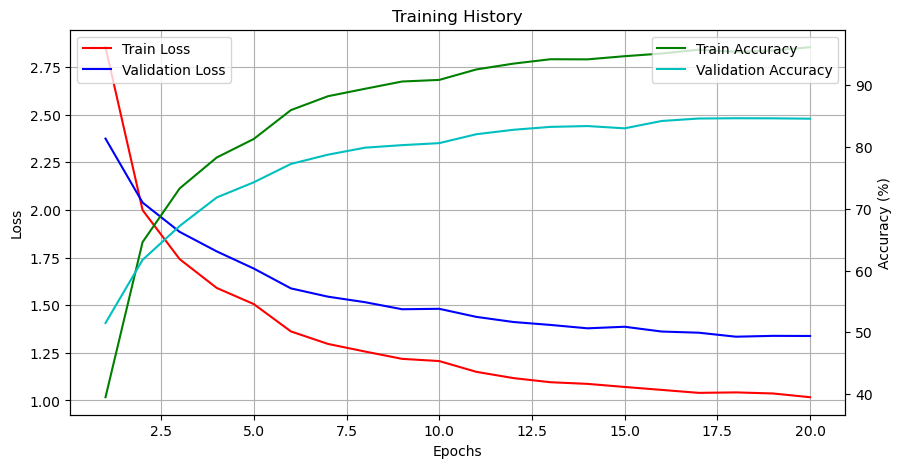

In [19]:
### Training Visualization

def plot_graph(history_path):
    df = pd.read_csv(history_path)
    
    epochs = df["epoch"]
    train_loss = df["train_loss"]
    val_loss = df["val_loss"]
    train_acc = df["train_acc"]
    val_acc = df["val_acc"]
    
    fig, ax1 = plt.subplots(figsize=(10, 5))
    
    # Loss
    ax1.plot(epochs, train_loss, "r-", label="Train Loss")
    ax1.plot(epochs, val_loss, "b-", label="Validation Loss")
    ax1.set_xlabel("Epochs")
    ax1.set_ylabel("Loss")
    ax1.legend(loc="upper left")
    ax1.grid(True)

    # Accuracy
    ax2 = ax1.twinx()
    ax2.plot(epochs, train_acc, "g-", label="Train Accuracy")
    ax2.plot(epochs, val_acc, "c-", label="Validation Accuracy")
    ax2.set_ylabel("Accuracy (%)")
    ax2.legend(loc="upper right") 
    
    plt.title("Training History")
    plt.show()
    
plot_graph("training_history/history.csv")

In [20]:
### Test Prediction Functions

def load_mapping(mapping_path):
    class_mapping = {}
    with open(mapping_path, "r") as f:
        for line in f:
            class_name, class_index = line.strip().split(",")
            class_mapping[int(class_index)] = class_name
    return class_mapping

def predict_image(image_path, model_path, mapping_path):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    
    class_mapping = load_mapping(mapping_path)
    
    num_classes = len(class_mapping)
    
    model = models.efficientnet_b3(weights=None)
    in_features = model.classifier[-1].in_features
    model.classifier = nn.Sequential(
        nn.BatchNorm1d(in_features),
        nn.Linear(in_features, 256),
        nn.ReLU(),
        nn.Dropout(0.45),
        nn.Linear(256, num_classes)
    )
    
    model.load_state_dict(torch.load(model_path, map_location=device))
    model.to(device)
    model.eval()
    
    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])
    
    image = Image.open(image_path).convert("RGB")
    image = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = model(image)
        _, prediction_idx = outputs.max(1)
        
    predicted_class = class_mapping[prediction_idx.item()]
    return predicted_class

In [21]:
### Test Prediction

IMAGE_PATH = "test_image.png"
MODEL_PATH = "models/best_model.pth"
MAPPING_PATH = "training_history/class_mapping.txt"

prediction = predict_image(IMAGE_PATH, MODEL_PATH, MAPPING_PATH)
print(f"Predicted Class: {prediction}")

Predicted Class: F18
